# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: 
- _Student No._: 20XX-XXXXX
- _Section_: THR-TX-X

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="errors.png" alt="Alt text" width=45%> 
<img src="func1_montecarlo.png" alt="Alt text" width=45%>
<img src="func2_montecarlo.png" alt="Alt text" width=45%>
<img src="func3_montecarlo.png" alt="Alt text" width=45%>


### Report discussion

#### Newton-Cotes Integration Methods

These methods for direct integration stay true to the spirit of the definition of the definite integral; that of areas of thin slices under curves. The chief difference is in the areas actually computed. While the formal definition uses rectangles, here we use areas that are more computationally efficient: trapezoids and areas under higher order polynomials. For our simple functions, it seems that the trapezoid method yields the least initial error, then the 3/8 and 1/3 Simpson's rule methods respectively. In all methods, the error asymptotically approaches zero as more and more steps (implying smaller and smaller step size) are accounted.

#### Monte Carlo Integration

Monte Carlo integration can be much more computationally intensive than Newton-Cotes, and instead of smaller step size, it is a larger number of sample points that leads to smaller error. However this approach to zero error is painfully slow, and even at 5,000 sample points error can still be significant. Error is also random; the monte carlo may need to be run multipe times to establish a reliable distribution for the expected error. So why bother? A big advantage is that it can find the areas of distributions that are not functions without any piecewise breaking of the domain. This makes it useful for finding areas bound inside of complexly-shaped curves. 
 
### Other comments
- No AI ever ever ever can touch my code
- As much as possible I dont rip any code straight from Gezerlis either; I prefer to come up with ideas (more often by brute force) and then implement them

---
## Section 2: Code

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

**Report Figures** (since there are three functions, there should be a total of 6 figures): 
For each function, plot the following: 

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

**Report discussion**: 
- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?



In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt

In [2]:
# functions

## x-axis values spanning from 0 to 5 (N*dx)

lowbound = 0
upbound = 5
dx = 0.0002

xs = np.arange(start=lowbound, stop=upbound, step=dx)

## polynomial
def func_a(xs):
    return xs

## sinusoid
def func_b(xs):
    return np.sin(2*np.pi*xs)

### problem functions

def func1(xs):
    return np.sqrt(9-4*xs**2)

def func2(xs):
    return -xs**2 + 1

def func3(xs):
    return np.sqrt(xs)*np.cos(xs)

In [3]:
# trapezoid integrator
def trapezoid_integrator(a, b, dx, func):
    
    xs = np.arange(start = a, stop = b, step = dx)
    
    dx = xs[1]-xs[0]
    cont = np.array([])
    cont2 = np.array([])
    for i in range(len(xs)-1):
        a = func(xs[i])
        b = func(xs[i+1])
        dy = 0.5*dx*(a+b)
        cont = np.append(cont, dy)
        n = np.sum(cont)
        cont2 = np.append(cont2, n)
    return (cont2, np.sum(cont))  # cont2 graphs indf. integ; sum takes def. integ.



In [4]:
# monte carlo integrator

#rng seed
rng = np.random.default_rng(911)


## defining point generator function
def rnd(x,y):
    xlow = np.min(x)
    xhigh = np.max(x)
    ylow = np.min(y)
    yhigh = np.max(y)
    return (rng.uniform(xlow, xhigh), rng.uniform(ylow, yhigh))


## monte carlo with plot


def signed_montecarlo_integrator(a, b, dx, func, N):

    xs = np.arange(start = a, stop = b, step = dx)
    
    fig, ax = plt.subplots()
    
    ### important constants
    pos = 0
    neg = 0
    reject = 0
    area = (np.max(xs)-np.min(xs))*(np.max(func(xs))-np.min(func(xs)))

    ### plotting the function
    ax.plot(xs, func(xs))
    
    for i in range(N):
        point = rnd(xs, func(xs))


        if point[1] > 0:  # points on the upper half
            if point[1] > func(point[0]):
                reject += 1
                ax.plot(point[0], point[1], 'o', markersize=1, color = "red")

            else:
                pos += 1
                ax.plot(point[0], point[1], 'o', markersize=1, color = "blue")
        
        else:   # points on the upper half
            if point[1] >= func(point[0]):
                neg += 1
                ax.plot(point[0], point[1], 'o', markersize=1, color = "orange")

            else:
                reject += 1
                ax.plot(point[0], point[1], 'o', markersize=1, color = "red")

    accept = pos - neg
    integral = (accept/N)*area
    return integral



In [5]:
# 1/3 Simpson's rule integrator, largely inspired by Gezerlis but implemented by hand

def onethird_simpson_integrator(a, b, dx, func):

    xss = np.arange(start = a, stop = b, step = dx)

    if len(xss) % 2 == 0:
        xs = xss

    else:
        xs = xss[0:-1]
    
    mult_array = 2*np.ones(np.size(xs))
    mult_array[1::2] = 4
    mult_array[0] = 1
    mult_array[-1] = 1
    
    return np.sum(mult_array*func(xs))*dx/3


In [6]:
# 3/8 Simpson's rule integrator

def threeeight_simpson_integrator(a, b, dx, func):

    xs = np.arange(start = a, stop = b, step = dx)
    
    mult_array = 3*np.ones(np.size(xs)-2)
    mult_array[1::3] = 2
    mult_array = np.concatenate(([1], mult_array, [1]))
    
    return 3*np.sum(mult_array*func(xs))*dx/8

## test

threeeight_simpson_integrator(0, 3/2, 0.0001, func1)

3.534251918112828

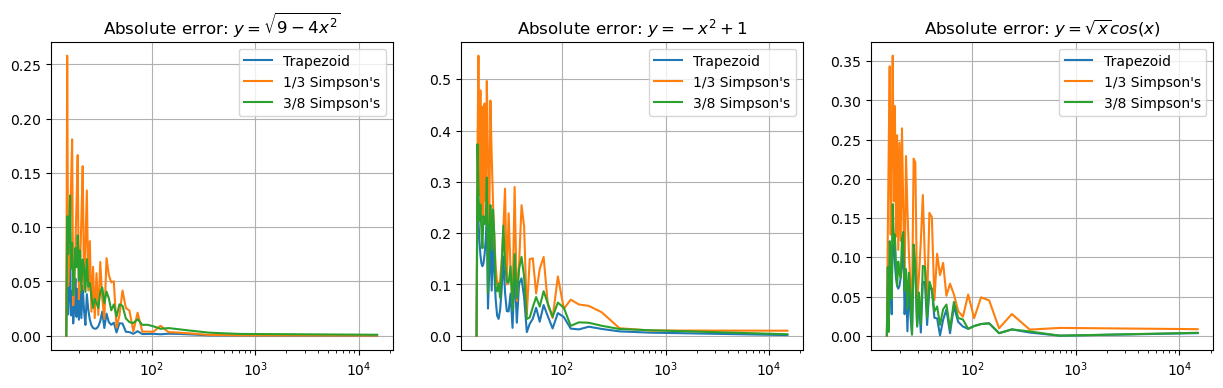

In [25]:
# plotting errors

## standard
standard1 = sp.integrate.quad(func1, 0, 3/2)[0]

standard2 = sp.integrate.quad(func2, -2, 2)[0]

standard3 = sp.integrate.quad(func3, 0, np.pi)[0]

## trapezoid

### array incrementing over small to large dx values
dxs = np.linspace(start = 0.0001, stop = 0.1)

### x-axis of the plot

ns = np.array([])
for i in range(np.size(dxs)):
    ns = np.append(ns, 1.5/dxs[i])

xs = ns[::-1]

### y-axis of plot

#### func 1

##### trapezoid
cont1 = np.array([])
for i in range(np.size(dxs)):
    ys = trapezoid_integrator(0, 3/2, dxs[-i], func1)[1]
    cont1 = np.append(cont1, np.abs(standard1-ys))


##### 1/3 simpson
cont2 = np.array([])
for i in range(np.size(dxs)):
    yt = onethird_simpson_integrator(0, 3/2, dxs[-i], func1)
    cont2 = np.append(cont2, np.abs(standard1-yt))

##### 3/8 simpson
cont3 = np.array([])
for i in range(np.size(dxs)):
    yu = threeeight_simpson_integrator(0, 3/2, dxs[-i], func1)
    cont3 = np.append(cont3, np.abs(standard1-yu))


#### func 2

##### trapezoid
cont4 = np.array([])
for i in range(np.size(dxs)):
    yv = trapezoid_integrator(-2, 2, dxs[-i], func2)[1]
    cont4 = np.append(cont4, np.abs(standard2-yv))


##### 1/3 simpson
cont5 = np.array([])
for i in range(np.size(dxs)):
    yw = onethird_simpson_integrator(-2, 2, dxs[-i], func2)
    cont5 = np.append(cont5, np.abs(standard2-yw))

##### 3/8 simpson
cont6 = np.array([])
for i in range(np.size(dxs)):
    yx = threeeight_simpson_integrator(-2, 2, dxs[-i], func2)
    cont6 = np.append(cont6, np.abs(standard2-yx))

#### func 3

##### trapezoid
cont7 = np.array([])
for i in range(np.size(dxs)):
    yy = trapezoid_integrator(0, np.pi, dxs[-i], func3)[1]
    cont7 = np.append(cont7, np.abs(standard3-yy))


##### 1/3 simpson
cont8 = np.array([])
for i in range(np.size(dxs)):
    yz = onethird_simpson_integrator(0, np.pi, dxs[-i], func3)
    cont8 = np.append(cont8, np.abs(standard3-yz))

##### 3/8 simpson
cont9 = np.array([])
for i in range(np.size(dxs)):
    ya = threeeight_simpson_integrator(0, np.pi, dxs[-i], func3)
    cont9 = np.append(cont9, np.abs(standard3-ya))


## monte carlo plots




## plotting
fig, (ax1, ax2, ax3) = plt.subplots(1,3, figsize = (15,4))


ax1.plot(xs, cont1, label="Trapezoid")
ax1.plot(xs, cont2, label="1/3 Simpson's")
ax1.plot(xs, cont3, label="3/8 Simpson's")
ax1.legend()
ax1.set_xscale('log')
ax1.grid()
ax1.set_title("Absolute error: $y=\sqrt{9-4x^2}$")

ax2.plot(xs, cont4, label="Trapezoid")
ax2.plot(xs, cont5, label="1/3 Simpson's")
ax2.plot(xs, cont6, label="3/8 Simpson's")
ax2.legend()
ax2.set_xscale('log')
ax2.grid()
ax2.set_title("Absolute error: $y=-x^2+1$")

ax3.plot(xs, cont7, label="Trapezoid")
ax3.plot(xs, cont8, label="1/3 Simpson's")
ax3.plot(xs, cont9, label="3/8 Simpson's")
ax3.legend()
ax3.grid()
ax3.set_xscale('log')
ax3.set_title("Absolute error: $y=\sqrt{x}cos(x)$")

plt.savefig("errors.png")

3.4994840396423483

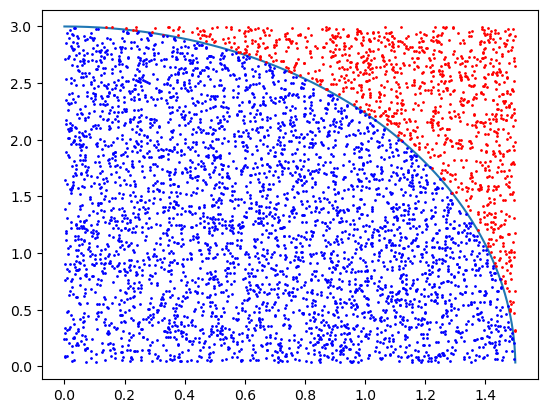

In [11]:
# monte carlo plot for func 1

signed_montecarlo_integrator(0, 3/2, 0.0001, func1, 5000)


-1.3407664799998524

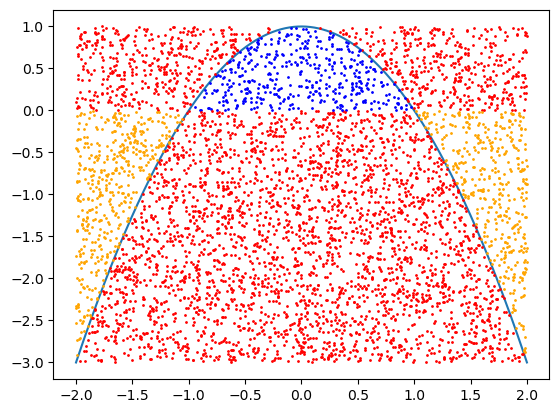

In [24]:
# monte carlo plot for func 2

signed_montecarlo_integrator(-2, 2, 0.0001, func2, 5000)

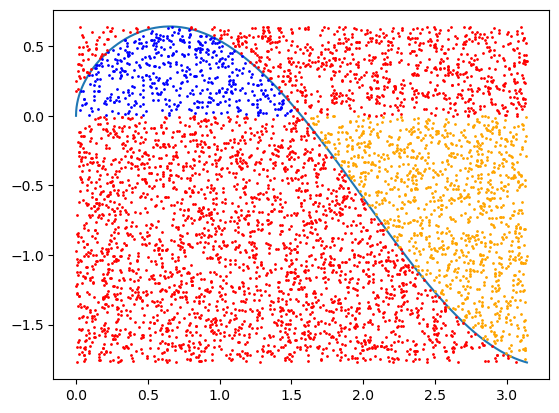

In [19]:
# monte carlo plot for func 3

signed_montecarlo_integrator(0, np.pi, 0.0001, func3, 5000)

plt.savefig("func3_montecarlo.png")

In [15]:
standard3

-0.8948314694841447